# Zinc XANES comparison

Compare the first eight held-out test structures, indices 0 through 7.
Every panel uses **Zn site 0** of the same structure.

| Panel | Source |
| --- | --- |
| RPC prediction | Raw site-0 output from the HTTP endpoint LightshowAI calls |
| Direct checkpoint | Raw site-0 output from `model/full_model.pth`, run in this notebook |
| Prediction overlay | The RPC and direct checkpoint curves on the same axes |
| DFT simulation | The supplied site-0 reference from `dataset/test_spectra.pt` |

The overlay checks integration parity. The DFT panel shows the reference used to evaluate model accuracy.
All panels and LightshowAI use the native GNN energy grid and raw intensities for this comparison.
The default LightshowAI curve averages the Zn sites. Select **Atom #1** in LightshowAI to see site 0.

Run this notebook from the repository root with the **Python (zinc)** kernel.
Start the Zinc service in a separate WSL terminal if needed.

```bash
source ~/miniconda3/etc/profile.d/conda.sh
conda activate zinc
cd /mnt/c/Users/anton/Documents/GitHub/GNN-XAS-ZnCl2aq
XAS_DEVICE=cpu XAS_PORT=8000 python server/xas_rpc_server.py
```

In [1]:
import json
import pickle
import sys
from pathlib import Path
from urllib.request import Request, urlopen

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import yaml

ROOT = Path.cwd()
RPC_URL = "http://127.0.0.1:8000/v1/predict"
test_indices = np.arange(8)

checkpoint_path = ROOT / "model/full_model.pth"
if not checkpoint_path.is_file():
    raise FileNotFoundError("Open the notebook from the GNN-XAS-ZnCl2aq repository root.")

sys.path.insert(0, str(ROOT / "code"))
from data import XASGraphDataset, collate_fn
from models import XASLightningModule

native_energy = np.linspace(8900, 9050, 1000)[333:733:2]

## 1. Load the structures and the DFT references

The dataset pairs each structure with a simulated spectrum for its first Zn atom.
We check that the atom is at index 0 before comparing any spectra.

In [2]:
with (ROOT / "dataset/test_structures.pkl").open("rb") as stream:
    test_structures = pickle.load(stream)

test_spectra = torch.load(
    ROOT / "dataset/test_spectra.pt", map_location="cpu", weights_only=True
)
structures = [test_structures[i] for i in test_indices]
dft_spectra = test_spectra[test_indices.tolist()].numpy()

assert all(structure[0].specie.symbol == "Zn" for structure in structures)
assert dft_spectra.shape == (len(test_indices), len(native_energy))

## 2. Generate the direct checkpoint predictions

This follows the model and graph setup in `generate-data-for-figures.ipynb`.
The GNN takes the graph as its input. The DFT targets are used only for comparison.

In [3]:
with (ROOT / "configs/config.yaml").open() as stream:
    config = yaml.safe_load(stream)

model = XASLightningModule(
    config["gnn"], config["head"], learning_rate=config["training"]["lr"]
)
model.load_state_dict(torch.load(checkpoint_path, map_location="cpu", weights_only=True))
model.eval()

dataset = XASGraphDataset(structures, dft_spectra, cutoff=config["gnn"]["cutoff"])
graphs, _, _ = collate_fn([dataset[i] for i in range(len(dataset))])
with torch.inference_mode():
    checkpoint_spectra = model(graphs).numpy()

assert checkpoint_spectra.shape == dft_spectra.shape

## 3. Request the same structures from the Zinc RPC

This sends the same structure-only payload as LightshowAI. The response has one
prediction per Zn site. Read key `"0"` to match the notebook and DFT reference.

In [4]:
rpc_spectra = []
for structure in structures:
    request = Request(
        RPC_URL,
        data=json.dumps({"structure": structure.as_dict()}).encode("utf-8"),
        headers={"Content-Type": "application/json"},
    )
    with urlopen(request, timeout=120) as response:
        result = json.load(response)

    np.testing.assert_allclose(result["energy_eV"], native_energy, rtol=0, atol=1e-8)
    rpc_spectra.append(result["spectra_by_site"]["0"])

rpc_spectra = np.asarray(rpc_spectra)
assert rpc_spectra.shape == checkpoint_spectra.shape

## 4. Compare the curves and the numerical errors

The overlay compares two inference paths. The table reports their largest pointwise
difference and the direct prediction's RMSE against the DFT simulation.

In [5]:
comparison = pd.DataFrame({
    "Test index": test_indices,
    "Max absolute difference (RPC vs checkpoint)": np.max(
        np.abs(rpc_spectra - checkpoint_spectra), axis=1
    ),
    "RMSE (checkpoint vs DFT)": np.sqrt(
        np.mean((checkpoint_spectra - dft_spectra) ** 2, axis=1)
    ),
})
comparison

,Test index,Max absolute difference (RPC vs checkpoint),RMSE (checkpoint vs DFT)
0,0,0.000000e+00,0.059883
1,1,0.000000e+00,0.063886
2,2,0.000000e+00,0.092149
3,3,0.000000e+00,0.030670
4,4,0.000000e+00,0.072628
5,5,0.000000e+00,0.074552
6,6,1.192093e-07,0.056873
7,7,2.384186e-07,0.043476


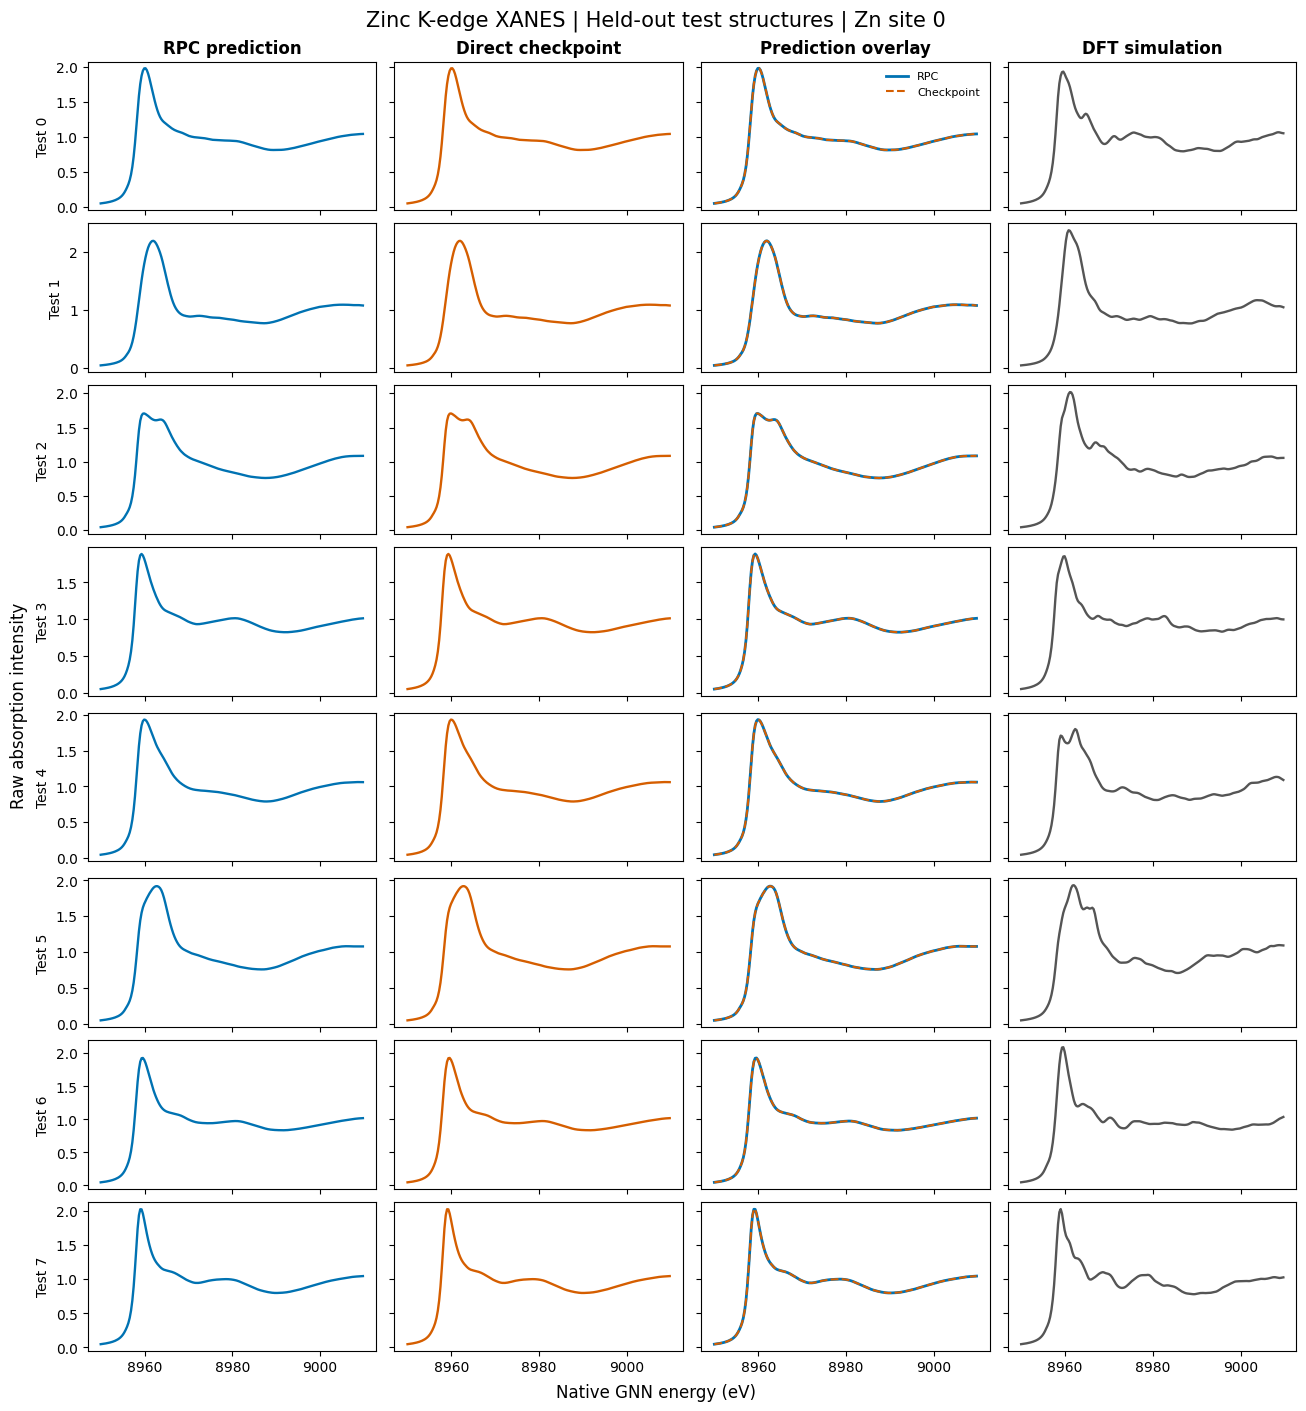

In [6]:
fig, axes = plt.subplots(
    len(test_indices), 4, figsize=(13, 14), sharex=True, sharey="row", layout="constrained"
)
titles = ["RPC prediction", "Direct checkpoint", "Prediction overlay", "DFT simulation"]
for axis, title in zip(axes[0], titles):
    axis.set_title(title, fontweight="bold")

for row, test_index in enumerate(test_indices):
    rpc, checkpoint, overlay, dft = axes[row]
    rpc.plot(native_energy, rpc_spectra[row], color="#0072B2", linewidth=1.7)
    checkpoint.plot(native_energy, checkpoint_spectra[row], color="#D55E00", linewidth=1.7)
    overlay.plot(native_energy, rpc_spectra[row], color="#0072B2", linewidth=2, label="RPC")
    overlay.plot(
        native_energy, checkpoint_spectra[row], color="#D55E00",
        linestyle="--", linewidth=1.5, label="Checkpoint"
    )
    dft.plot(native_energy, dft_spectra[row], color="#555555", linewidth=1.7)
    rpc.set_ylabel(f"Test {test_index}")

axes[0, 2].legend(loc="upper right", fontsize=8, frameon=False)
fig.suptitle("Zinc K-edge XANES | Held-out test structures | Zn site 0", fontsize=15)
fig.supxlabel("Native GNN energy (eV)")
fig.supylabel("Raw absorption intensity")
plt.show()